# Telco Customer Churn Prediction Using Random Forest and XGBoost

**Roll Numbers:** 2520030248, 2520030273, 2520030270
**Department:** Computer Science Engineering, KLH University

This notebook builds a machine learning system that predicts whether a telecom
customer will churn (cancel their service), using **Random Forest** and
**XGBoost** classifiers. We compare both models on Accuracy, Precision, Recall,
F1-score, and ROC-AUC.

**Dataset:** IBM Telco Customer Churn — 7,043 customers, 21 columns covering
demographics, account information, and subscribed services.

## 1. Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                              f1_score, roc_auc_score, confusion_matrix,
                              classification_report, roc_curve)

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (7, 5)

## 2. Load the Dataset

We use `telco_churn.csv` (7,043 rows, 21 columns): demographics (gender, senior
citizen, partner, dependents), account info (tenure, contract, payment method,
monthly/total charges), and subscribed services (phone, internet, streaming, etc.).

In [2]:
df = pd.read_csv('telco_churn.csv')
print("Dataset shape:", df.shape)
df.head()

Dataset shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [4]:
# TotalCharges is stored as text and has some blank entries for brand-new customers
# (tenure = 0, so they haven't been billed yet). Let's check.
blank_mask = df['TotalCharges'].astype(str).str.strip() == ''
print("Blank TotalCharges rows:", blank_mask.sum())
df[blank_mask][['customerID', 'tenure', 'MonthlyCharges', 'TotalCharges']]

Blank TotalCharges rows: 11


,customerID,tenure,MonthlyCharges,TotalCharges
488,4472-LVYGI,0,52.55,
753,3115-CZMZD,0,20.25,
936,5709-LVOEQ,0,80.85,
1082,4367-NUYAO,0,25.75,
1340,1371-DWPAZ,0,56.05,
3331,7644-OMVMY,0,19.85,
3826,3213-VVOLG,0,25.35,
4380,2520-SGTTA,0,20.00,
5218,2923-ARZLG,0,19.70,
6670,4075-WKNIU,0,73.35,


## 3. Exploratory Data Analysis (EDA)

/tmp/ipykernel_99/1798913846.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Churn', data=df, palette=['#2E86AB', '#E63946'])


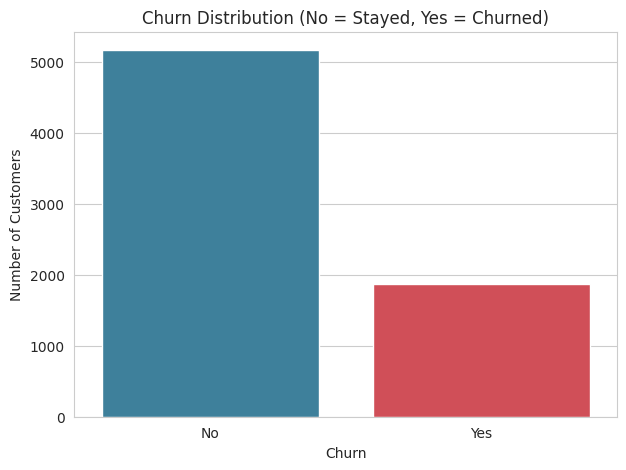

Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


In [5]:
plt.figure()
sns.countplot(x='Churn', data=df, palette=['#2E86AB', '#E63946'])
plt.title('Churn Distribution (No = Stayed, Yes = Churned)')
plt.ylabel('Number of Customers')
plt.show()

print(df['Churn'].value_counts(normalize=True) * 100)

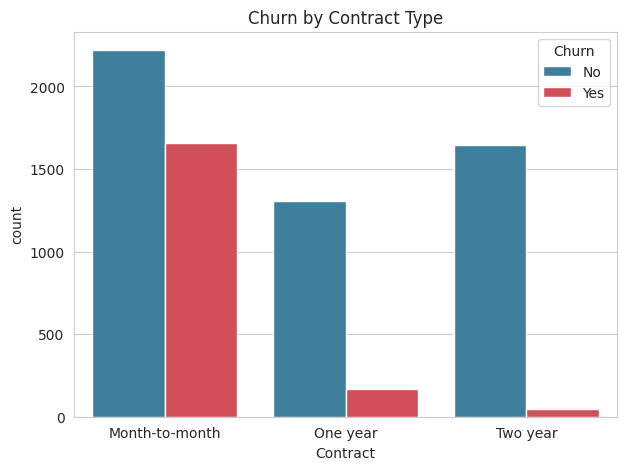

In [6]:
plt.figure()
sns.countplot(x='Contract', hue='Churn', data=df, palette=['#2E86AB', '#E63946'])
plt.title('Churn by Contract Type')
plt.show()

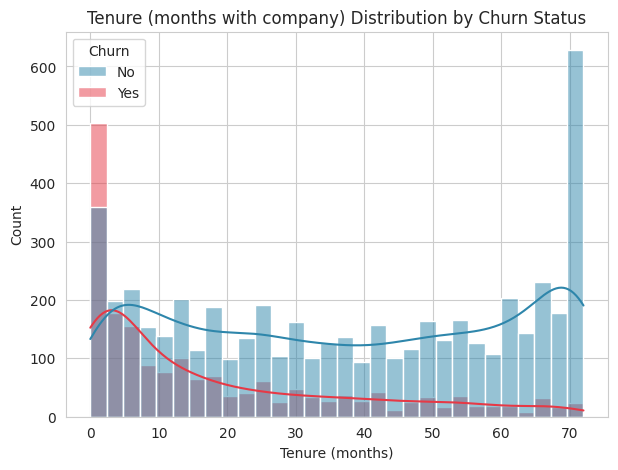

In [7]:
df['tenure_num'] = pd.to_numeric(df['tenure'], errors='coerce')
plt.figure()
sns.histplot(data=df, x='tenure_num', hue='Churn', bins=30, kde=True, palette=['#2E86AB', '#E63946'])
plt.title('Tenure (months with company) Distribution by Churn Status')
plt.xlabel('Tenure (months)')
plt.show()

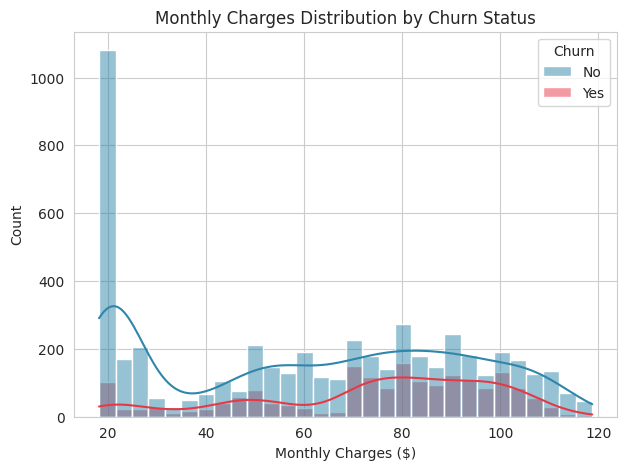

In [8]:
plt.figure()
df['MonthlyCharges_num'] = pd.to_numeric(df['MonthlyCharges'], errors='coerce')
sns.histplot(data=df, x='MonthlyCharges_num', hue='Churn', bins=30, kde=True, palette=['#2E86AB', '#E63946'])
plt.title('Monthly Charges Distribution by Churn Status')
plt.xlabel('Monthly Charges ($)')
plt.show()

## 4. Data Preprocessing

Steps:
1. Drop `customerID` — just an identifier.
2. Fix `TotalCharges` — convert to numeric, fill blanks with 0 (these are brand-new
   customers with tenure = 0, so they genuinely haven't been billed yet).
3. Encode the target `Churn` (Yes=1, No=0).
4. Encode simple Yes/No columns as 0/1.
5. One-hot encode multi-category columns (InternetService, Contract, PaymentMethod, etc.).
6. Train/test split (80/20), stratified.
7. Scale features.

In [9]:
data = df.drop(columns=['customerID']).copy()

# Fix TotalCharges
data['TotalCharges'] = pd.to_numeric(data['TotalCharges'], errors='coerce')
data['TotalCharges'] = data['TotalCharges'].fillna(0)

# Encode target
data['Churn'] = data['Churn'].map({'Yes': 1, 'No': 0})

# Encode simple binary columns
binary_cols = ['gender', 'Partner', 'Dependents', 'PhoneService', 'PaperlessBilling']
for col in binary_cols:
    le = LabelEncoder()
    data[col] = le.fit_transform(data[col])  # e.g. Female=0/Male=1, No=0/Yes=1

# One-hot encode multi-category columns
multi_cat_cols = ['MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup',
                   'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies',
                   'Contract', 'PaymentMethod']
data = pd.get_dummies(data, columns=multi_cat_cols, drop_first=True)

# Drop helper columns created during EDA
data = data.drop(columns=['tenure_num', 'MonthlyCharges_num'], errors='ignore')

X = data.drop(columns=['Churn'])
y = data['Churn']

print("Total features used:", X.shape[1])
print(list(X.columns))
X.head()

Total features used: 30
['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'PaperlessBilling', 'MonthlyCharges', 'TotalCharges', 'MultipleLines_No phone service', 'MultipleLines_Yes', 'InternetService_Fiber optic', 'InternetService_No', 'OnlineSecurity_No internet service', 'OnlineSecurity_Yes', 'OnlineBackup_No internet service', 'OnlineBackup_Yes', 'DeviceProtection_No internet service', 'DeviceProtection_Yes', 'TechSupport_No internet service', 'TechSupport_Yes', 'StreamingTV_No internet service', 'StreamingTV_Yes', 'StreamingMovies_No internet service', 'StreamingMovies_Yes', 'Contract_One year', 'Contract_Two year', 'PaymentMethod_Credit card (automatic)', 'PaymentMethod_Electronic check', 'PaymentMethod_Mailed check']


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,PaperlessBilling,MonthlyCharges,TotalCharges,MultipleLines_No phone service,...,TechSupport_Yes,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,0,1,0,1,0,1,29.85,29.85,True,...,False,False,False,False,False,False,False,False,True,False
1,1,0,0,0,34,1,0,56.95,1889.50,False,...,False,False,False,False,False,True,False,False,False,True
2,1,0,0,0,2,1,1,53.85,108.15,False,...,False,False,False,False,False,False,False,False,False,True
3,1,0,0,0,45,0,0,42.30,1840.75,True,...,True,False,False,False,False,True,False,False,False,False
4,0,0,0,0,2,1,1,70.70,151.65,False,...,False,False,False,False,False,False,False,False,True,False


In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Train size:", X_train.shape, " Test size:", X_test.shape)

Train size: (5634, 30)  Test size: (1409, 30)


## 5. Model 1 — Random Forest

In [11]:
rf = RandomForestClassifier(
    n_estimators=300, max_depth=10, random_state=42, class_weight='balanced'
)
rf.fit(X_train_scaled, y_train)

rf_pred = rf.predict(X_test_scaled)
rf_proba = rf.predict_proba(X_test_scaled)[:, 1]

## 6. Model 2 — XGBoost

In [12]:
pos_weight = y_train.value_counts()[0] / y_train.value_counts()[1]

xgb = XGBClassifier(
    n_estimators=300, max_depth=6, learning_rate=0.05,
    eval_metric='logloss', random_state=42,
    scale_pos_weight=pos_weight
)
xgb.fit(X_train_scaled, y_train)

xgb_pred = xgb.predict(X_test_scaled)
xgb_proba = xgb.predict_proba(X_test_scaled)[:, 1]

## 7. Model Evaluation

In [13]:
def get_metrics(name, y_true, y_pred, y_proba):
    return {
        'Model': name,
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred),
        'Recall': recall_score(y_true, y_pred),
        'F1-score': f1_score(y_true, y_pred),
        'ROC-AUC': roc_auc_score(y_true, y_proba)
    }

results = pd.DataFrame([
    get_metrics('Random Forest', y_test, rf_pred, rf_proba),
    get_metrics('XGBoost', y_test, xgb_pred, xgb_proba)
]).set_index('Model')

results.round(4)

,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
Random Forest,0.7665,0.5446,0.7353,0.6257,0.8422
XGBoost,0.7566,0.5295,0.7433,0.6185,0.8336


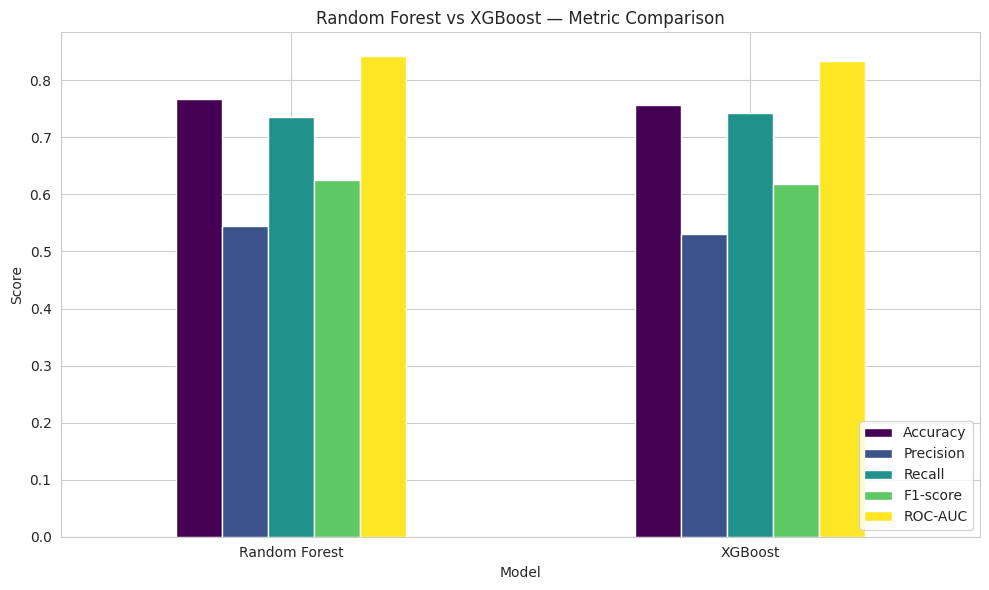

In [14]:
results.round(3).plot(kind='bar', figsize=(10,6), colormap='viridis')
plt.title('Random Forest vs XGBoost — Metric Comparison')
plt.ylabel('Score')
plt.xticks(rotation=0)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

### Confusion Matrices

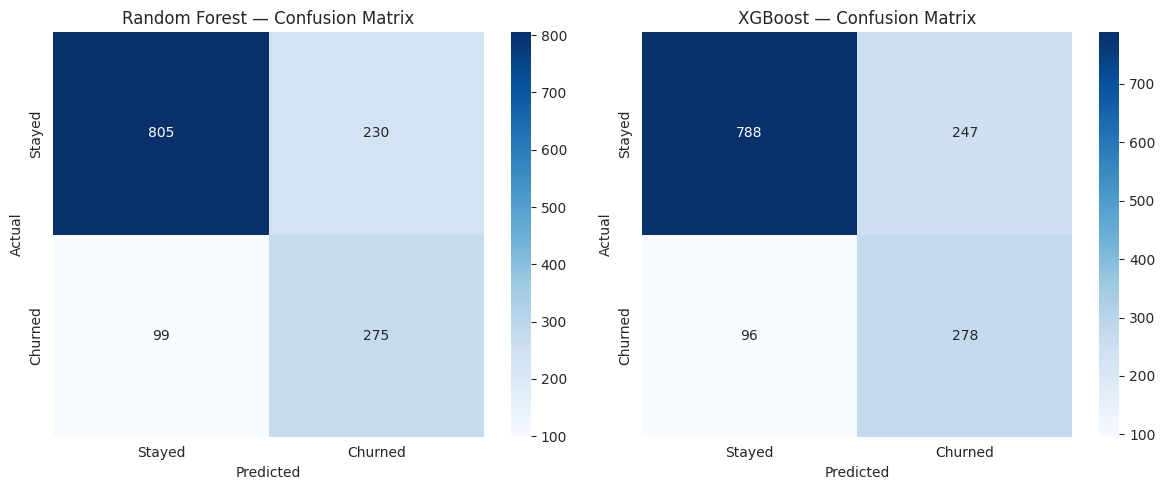

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, (name, pred) in zip(axes, [('Random Forest', rf_pred), ('XGBoost', xgb_pred)]):
    cm = confusion_matrix(y_test, pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=['Stayed', 'Churned'], yticklabels=['Stayed', 'Churned'])
    ax.set_title(f'{name} — Confusion Matrix')
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')

plt.tight_layout()
plt.show()

### ROC Curves

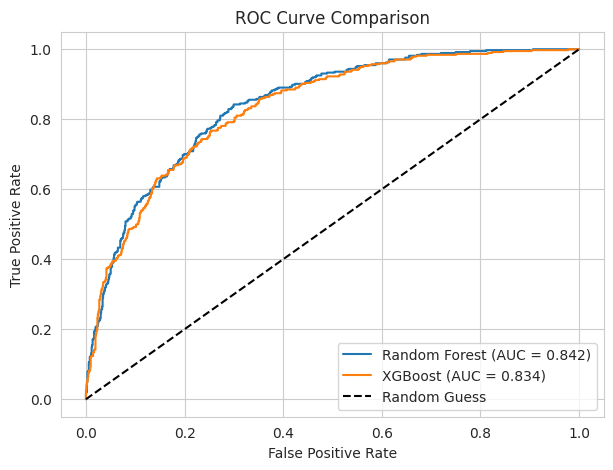

In [16]:
fpr_rf, tpr_rf, _ = roc_curve(y_test, rf_proba)
fpr_xgb, tpr_xgb, _ = roc_curve(y_test, xgb_proba)

plt.figure()
plt.plot(fpr_rf, tpr_rf, label=f"Random Forest (AUC = {roc_auc_score(y_test, rf_proba):.3f})")
plt.plot(fpr_xgb, tpr_xgb, label=f"XGBoost (AUC = {roc_auc_score(y_test, xgb_proba):.3f})")
plt.plot([0, 1], [0, 1], 'k--', label='Random Guess')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve Comparison')
plt.legend()
plt.show()

### Detailed Classification Reports

In [17]:
print("Random Forest:\n", classification_report(y_test, rf_pred, target_names=['Stayed','Churned']))
print("XGBoost:\n", classification_report(y_test, xgb_pred, target_names=['Stayed','Churned']))

Random Forest:
               precision    recall  f1-score   support

      Stayed       0.89      0.78      0.83      1035
     Churned       0.54      0.74      0.63       374

    accuracy                           0.77      1409
   macro avg       0.72      0.76      0.73      1409
weighted avg       0.80      0.77      0.78      1409

XGBoost:
               precision    recall  f1-score   support

      Stayed       0.89      0.76      0.82      1035
     Churned       0.53      0.74      0.62       374

    accuracy                           0.76      1409
   macro avg       0.71      0.75      0.72      1409
weighted avg       0.80      0.76      0.77      1409



## 8. Feature Importance

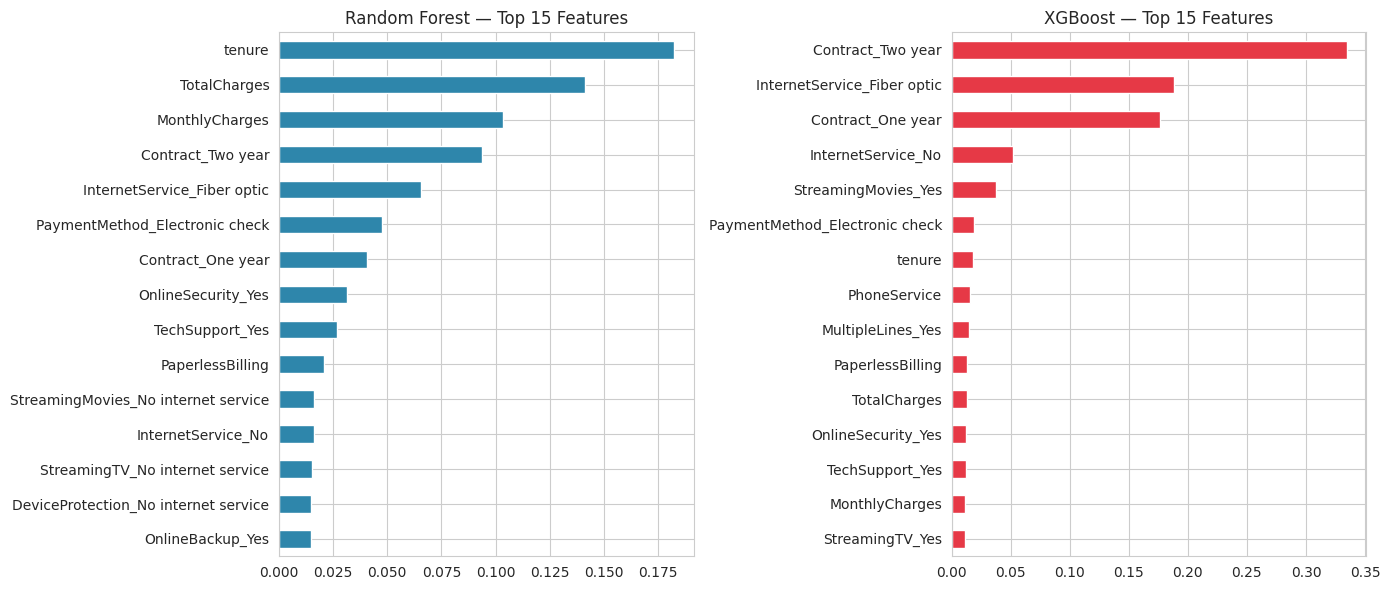

In [18]:
rf_importance = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False).head(15)
xgb_importance = pd.Series(xgb.feature_importances_, index=X.columns).sort_values(ascending=False).head(15)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
rf_importance.plot(kind='barh', ax=axes[0], color='#2E86AB')
axes[0].invert_yaxis()
axes[0].set_title('Random Forest — Top 15 Features')

xgb_importance.plot(kind='barh', ax=axes[1], color='#E63946')
axes[1].invert_yaxis()
axes[1].set_title('XGBoost — Top 15 Features')

plt.tight_layout()
plt.show()

## 9. Which specific customers are most likely to leave?

`predict_proba()` gives each customer a **risk score** between 0 and 1. We use
this to build two views:
- **All predicted churners:** every customer whose risk score crosses the 0.5
  decision line.
- **Top 200 shortlist:** just the 200 highest-risk customers.

In [19]:
risk_table = X_test.copy()
risk_table['Actual_Churn'] = y_test.values
risk_table['RF_Risk_Score'] = rf_proba
risk_table['XGB_Risk_Score'] = xgb_proba

all_predicted_churners = risk_table[risk_table['RF_Risk_Score'] >= 0.5].sort_values('RF_Risk_Score', ascending=False)
print(f"The model predicts {len(all_predicted_churners)} out of {len(risk_table)} test customers will churn.")
all_predicted_churners[['tenure', 'MonthlyCharges', 'TotalCharges',
                         'Actual_Churn', 'RF_Risk_Score', 'XGB_Risk_Score']].head(20)

The model predicts 505 out of 1409 test customers will churn.


,tenure,MonthlyCharges,TotalCharges,Actual_Churn,RF_Risk_Score,XGB_Risk_Score
4585,1,85.05,85.05,1,0.943748,0.975896
3380,1,95.10,95.10,1,0.937179,0.958615
6623,1,76.45,76.45,1,0.934851,0.971634
2194,1,79.50,79.50,1,0.929652,0.965366
6866,1,95.45,95.45,1,0.927128,0.977033
1731,1,69.60,69.60,1,0.923480,0.979136
1739,1,69.90,69.90,1,0.922389,0.951615
2927,1,69.90,69.90,0,0.922389,0.951615
809,1,69.55,69.55,1,0.921865,0.965113
3346,2,84.05,186.05,0,0.920634,0.945530


In [20]:
full_hit_rate = all_predicted_churners['Actual_Churn'].sum() / len(all_predicted_churners) * 100
print(f"Of all {len(all_predicted_churners)} customers the model flagged as likely to churn, "
      f"{all_predicted_churners['Actual_Churn'].sum()} out of {len(all_predicted_churners)} "
      f"({full_hit_rate:.0f}%) actually churned.")

Of all 505 customers the model flagged as likely to churn, 275 out of 505 (54%) actually churned.


In [21]:
top_risk_customers = risk_table.sort_values('RF_Risk_Score', ascending=False).head(200)
print("Top 200 customers most likely to churn (highest risk first):")
top_risk_customers[['tenure', 'MonthlyCharges', 'TotalCharges',
                     'Actual_Churn', 'RF_Risk_Score', 'XGB_Risk_Score']].head(20)

Top 200 customers most likely to churn (highest risk first):


,tenure,MonthlyCharges,TotalCharges,Actual_Churn,RF_Risk_Score,XGB_Risk_Score
4585,1,85.05,85.05,1,0.943748,0.975896
3380,1,95.10,95.10,1,0.937179,0.958615
6623,1,76.45,76.45,1,0.934851,0.971634
2194,1,79.50,79.50,1,0.929652,0.965366
6866,1,95.45,95.45,1,0.927128,0.977033
1731,1,69.60,69.60,1,0.923480,0.979136
2927,1,69.90,69.90,0,0.922389,0.951615
1739,1,69.90,69.90,1,0.922389,0.951615
809,1,69.55,69.55,1,0.921865,0.965113
3346,2,84.05,186.05,0,0.920634,0.945530


In [22]:
hit_rate = top_risk_customers['Actual_Churn'].sum() / len(top_risk_customers) * 100
print(f"Of the top 200 customers we flagged as highest risk, "
      f"{top_risk_customers['Actual_Churn'].sum()} out of 200 ({hit_rate:.0f}%) actually churned.")

Of the top 200 customers we flagged as highest risk, 145 out of 200 (72%) actually churned.


## 10. Conclusion

- Both **Random Forest** and **XGBoost** were trained on 7,043 telco customer
  records using demographic, account, and service-subscription features.
- Model performance was evaluated using Accuracy, Precision, Recall, F1-score, and
  ROC-AUC.
- Contract type (month-to-month vs long-term), tenure, and monthly charges
  consistently show up as the strongest predictors of churn.
- The better-performing model can be deployed to flag high-risk customers early,
  so retention teams can act with personalized offers before the customer
  actually leaves.

**Possible extensions:** hyperparameter tuning, SHAP values for explainability,
and deploying the final model as a simple Flask/Streamlit app.